In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix

In [7]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

df = pd.read_csv("heart_disease.csv")

print(df.head())
print(df.columns.tolist())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [8]:
baseline_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, C=1.0, random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=None, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=None, random_state=42
    ),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=1.0, kernel="rbf"))
    ])
}

tuned_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000, C=0.1, random_state=42
        ))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, min_samples_split=10,
        min_samples_leaf=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8,
        min_samples_split=5, min_samples_leaf=2,
        random_state=42
    ),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=9, weights="distance"))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=0.5, kernel="rbf"))
    ])
}

In [9]:
def manual_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    specificity = tn / max(tn + fp, 1)

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1-score": f1
    }

In [10]:
df = df.drop_duplicates().copy()

X = df.drop(columns=["target"])
y = df["target"]

X = pd.get_dummies(X, drop_first=True, dtype=int)

imputer = SimpleImputer(strategy="median")
X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (20, 13)
Testing features: (5, 13)
Training target: (20,)
Testing target: (5,)


In [11]:
results = []
trained_models = {}

for name in baseline_models:
    for stage, model_dict in [
        ("Before Tuning", baseline_models),
        ("After Tuning", tuned_models)
    ]:
        model = clone(model_dict[name])
        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        train_metrics = manual_metrics(y_train, train_pred)
        test_metrics = manual_metrics(y_test, test_pred)

        results.append({
            "Model": name,
            "Stage": stage,
            "Train Accuracy": train_metrics["Accuracy"],
            "Test Accuracy": test_metrics["Accuracy"],
            "Precision": test_metrics["Precision"],
            "Recall": test_metrics["Recall"],
            "Specificity": test_metrics["Specificity"],
            "F1-score": test_metrics["F1-score"],
            "Generalization Gap": (
                train_metrics["Accuracy"] - test_metrics["Accuracy"]
            )
        })

        trained_models[(name, stage)] = model

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

              Model         Stage  Train Accuracy  Test Accuracy  Precision  Recall  Specificity  F1-score  Generalization Gap
Logistic Regression Before Tuning            1.00            0.8     0.7500  1.0000          0.5    0.8571                0.20
Logistic Regression  After Tuning            1.00            0.6     0.6000  1.0000          0.0    0.7500                0.40
      Decision Tree Before Tuning            1.00            0.4     0.5000  0.3333          0.5    0.4000                0.60
      Decision Tree  After Tuning            0.90            0.2     0.3333  0.3333          0.0    0.3333                0.70
      Random Forest Before Tuning            1.00            0.6     0.6000  1.0000          0.0    0.7500                0.40
      Random Forest  After Tuning            1.00            0.6     0.6000  1.0000          0.0    0.7500                0.40
                KNN Before Tuning            0.95            0.6     0.6000  1.0000          0.0    0.7500     

In [12]:
metrics_to_compare = [
    "Train Accuracy",
    "Test Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-score"
]

before = (
    results_df[results_df["Stage"] == "Before Tuning"]
    .set_index("Model")
)

after = (
    results_df[results_df["Stage"] == "After Tuning"]
    .set_index("Model")
)

improvement = after[metrics_to_compare] - before[metrics_to_compare]

print("Absolute improvement (percentage points):")
print((improvement * 100).round(2))

print("\nTest accuracy improvement:")
print((improvement["Test Accuracy"] * 100).round(2))

Absolute improvement (percentage points):
                     Train Accuracy  Test Accuracy  Precision  Recall  \
Model                                                                   
Logistic Regression             0.0          -20.0     -15.00     0.0   
Decision Tree                 -10.0          -20.0     -16.67     0.0   
Random Forest                   0.0            0.0       0.00     0.0   
KNN                             5.0            0.0       0.00     0.0   
SVM                           -10.0          -20.0     -15.00     0.0   

                     Specificity  F1-score  
Model                                       
Logistic Regression        -50.0    -10.71  
Decision Tree              -50.0     -6.67  
Random Forest                0.0      0.00  
KNN                          0.0      0.00  
SVM                        -50.0    -10.71  

Test accuracy improvement:
Model
Logistic Regression   -20.0
Decision Tree         -20.0
Random Forest           0.0
KNN          

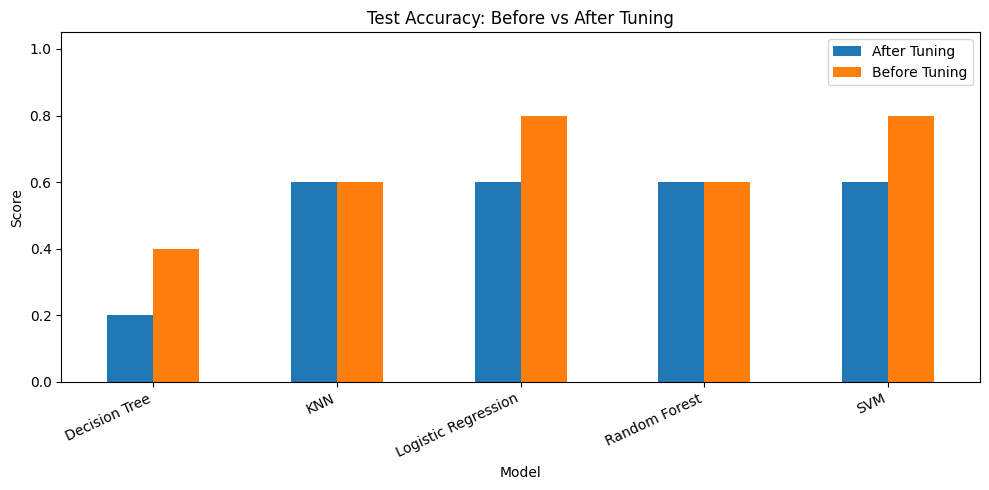

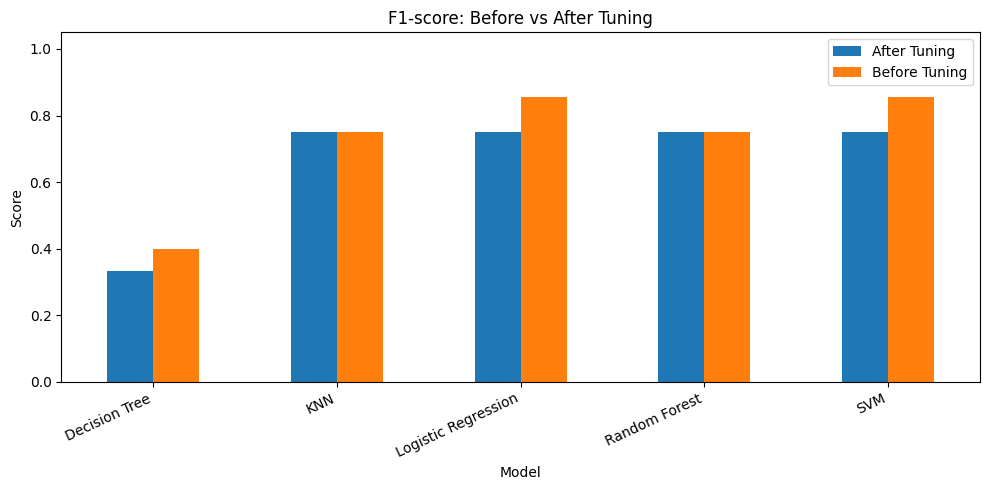

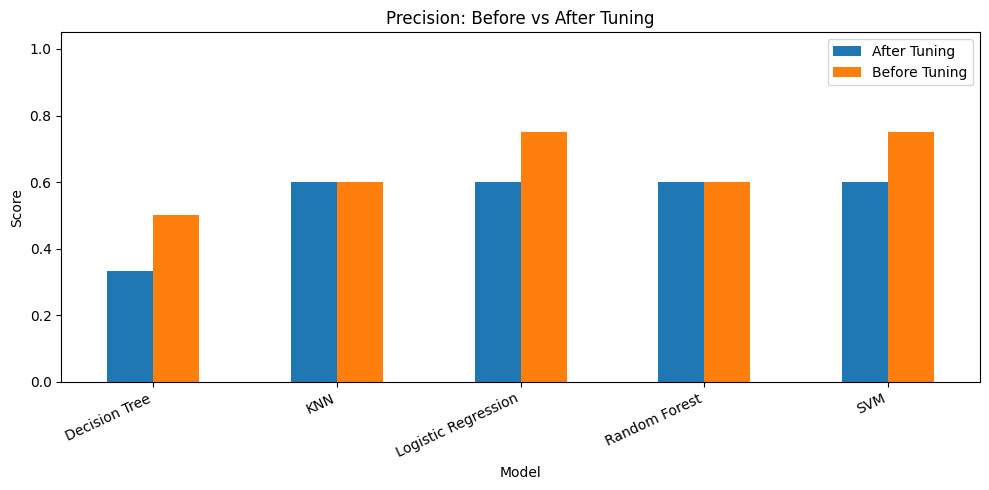

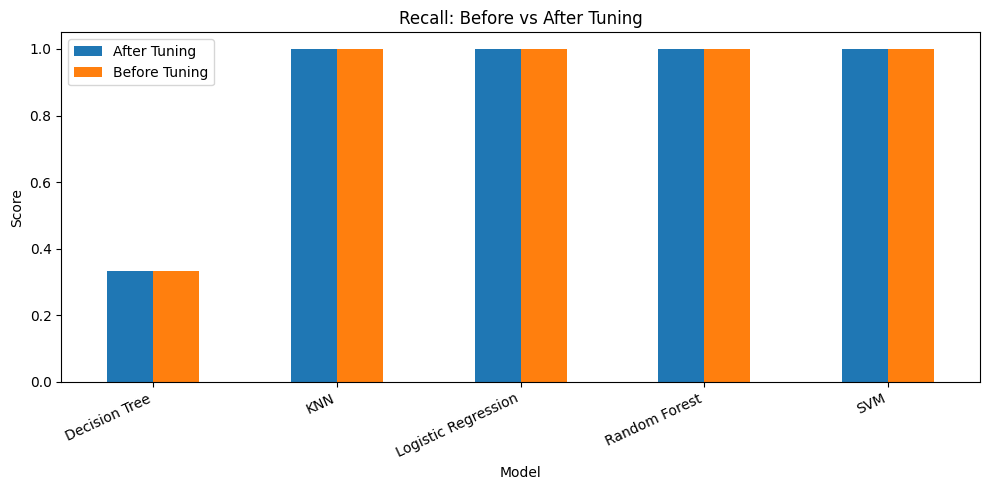

In [13]:
for metric in ["Test Accuracy", "F1-score", "Precision", "Recall"]:
    pivot = results_df.pivot(
        index="Model",
        columns="Stage",
        values=metric
    )

    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_title(f"{metric}: Before vs After Tuning")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Model")
    plt.xticks(rotation=25, ha="right")
    plt.legend(title="")
    plt.tight_layout()
    plt.show()

Generalization gaps:
Stage                After Tuning  Before Tuning
Model                                           
Decision Tree                 0.7           0.60
KNN                           0.4           0.35
Logistic Regression           0.4           0.20
Random Forest                 0.4           0.40
SVM                           0.3           0.20


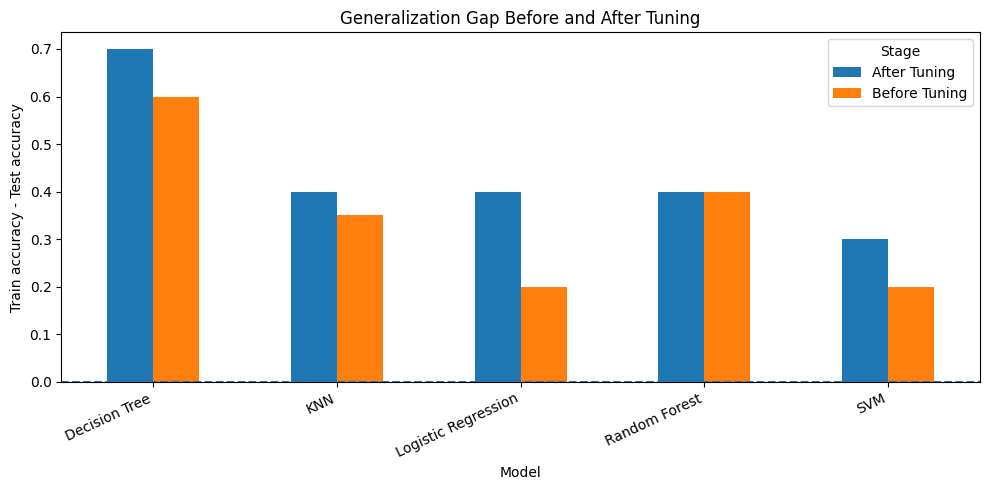

In [14]:
gap_comparison = results_df.pivot(
    index="Model",
    columns="Stage",
    values="Generalization Gap"
)

print("Generalization gaps:")
print(gap_comparison.round(4))

gap_comparison.plot(kind="bar", figsize=(10, 5))
plt.axhline(0, linestyle="--")
plt.ylabel("Train accuracy - Test accuracy")
plt.title("Generalization Gap Before and After Tuning")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

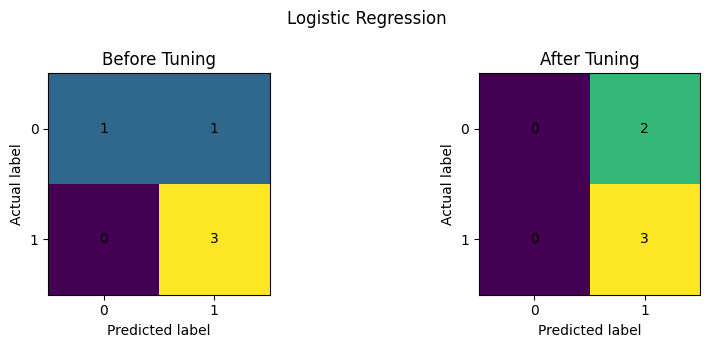

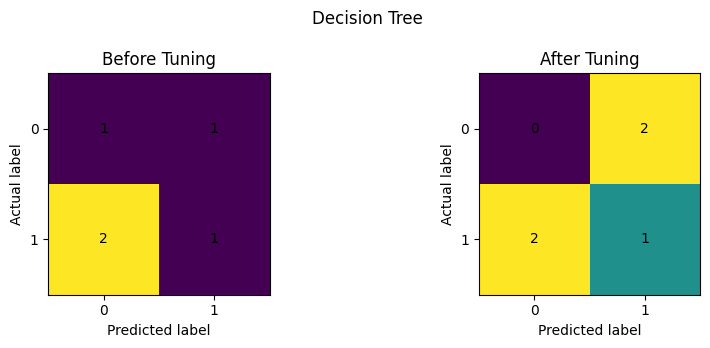

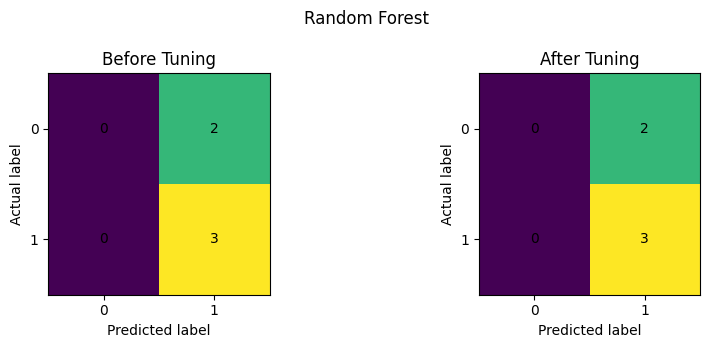

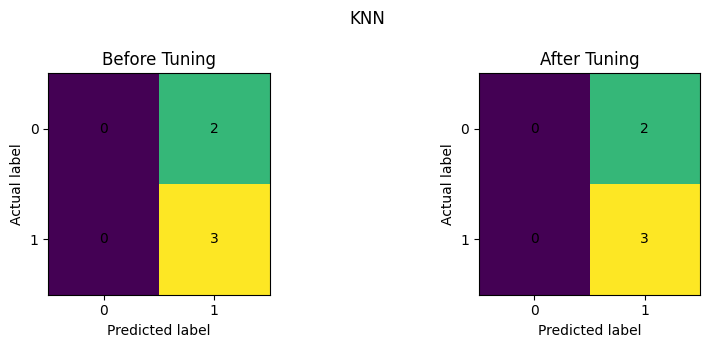

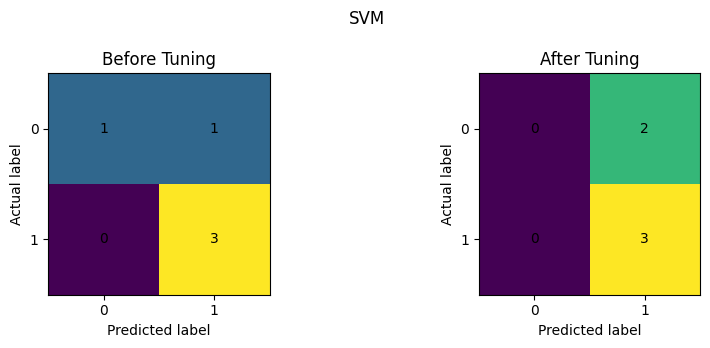

In [15]:
for name in baseline_models:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

    for ax, stage in zip(
        axes, ["Before Tuning", "After Tuning"]
    ):
        model = trained_models[(name, stage)]
        pred = model.predict(X_test)
        cm = confusion_matrix(y_test, pred, labels=[0, 1])

        ax.imshow(cm, interpolation="nearest")
        ax.set_title(stage)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("Actual label")
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(cm[i, j]),
                        ha="center", va="center")

    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

In [16]:
from sklearn.exceptions import ConvergenceWarning
import warnings

for stage, model_dict in [
    ("Before Tuning", baseline_models),
    ("After Tuning", tuned_models)
]:
    model = clone(model_dict["Logistic Regression"])

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, y_train)

    lr = model.named_steps["model"]

    print(
        stage,
        "| Iterations:", lr.n_iter_.max(),
        "| Convergence warning:",
        any(issubclass(w.category, ConvergenceWarning) for w in caught)
    )

Before Tuning | Iterations: 9 | Convergence warning: False
After Tuning | Iterations: 8 | Convergence warning: False


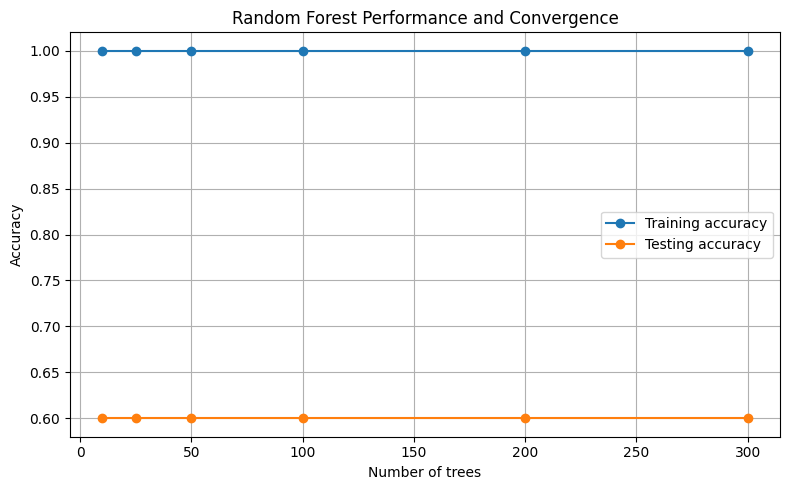

In [17]:
tree_counts = [10, 25, 50, 100, 200, 300]
train_scores = []
test_scores = []

for n in tree_counts:
    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_scores.append(
        manual_metrics(y_train, model.predict(X_train))["Accuracy"]
    )
    test_scores.append(
        manual_metrics(y_test, model.predict(X_test))["Accuracy"]
    )

plt.figure(figsize=(8, 5))
plt.plot(tree_counts, train_scores, marker="o", label="Training accuracy")
plt.plot(tree_counts, test_scores, marker="o", label="Testing accuracy")
plt.xlabel("Number of trees")
plt.ylabel("Accuracy")
plt.title("Random Forest Performance and Convergence")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_nn = np.asarray(y_train).astype("float32")
y_test_nn = np.asarray(y_test).astype("float32")

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (20, 13)
Testing shape: (5, 13)


In [20]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

initial_lr = 0.01

optimizer = tf.keras.optimizers.SGD(
    learning_rate=initial_lr,
    momentum=0.9
)

model.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
epochs = 100
batch_size = 16

learning_rate = 0.01
min_lr = 0.0001
factor = 0.5

patience = 3
early_stopping_patience = 10

best_val_loss = float("inf")
wait = 0
early_wait = 0

history = {
    "loss": [],
    "val_loss": [],
    "accuracy": [],
    "val_accuracy": [],
    "learning_rate": []
}

best_weights = None

for epoch in range(epochs):

    train_history = model.fit(
        X_train_scaled,
        y_train_nn,
        validation_split=0.2,
        epochs=1,
        batch_size=batch_size,
        verbose=0,
        shuffle=True
    )

    train_loss = train_history.history["loss"][0]
    val_loss = train_history.history["val_loss"][0]
    train_acc = train_history.history["accuracy"][0]
    val_acc = train_history.history["val_accuracy"][0]

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)
    history["learning_rate"].append(learning_rate)

    if val_loss < best_val_loss - 0.0001:
        best_val_loss = val_loss
        best_weights = model.get_weights()
        wait = 0
        early_wait = 0
    else:
        wait += 1
        early_wait += 1

    if wait >= patience and learning_rate > min_lr:
        learning_rate = max(min_lr, learning_rate * factor)

        model.optimizer.learning_rate.assign(learning_rate)

        print(
            f"Epoch {epoch + 1}: Learning rate reduced to "
            f"{learning_rate:.6f}"
        )

        wait = 0

    if early_wait >= early_stopping_patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

    print(
        f"Epoch {epoch + 1:03d} | "
        f"Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"LR: {learning_rate:.6f}"
    )

if best_weights is not None:
    model.set_weights(best_weights)

Epoch 001 | Loss: 1.0146 | Val Loss: 0.7684 | Val Accuracy: 0.5000 | LR: 0.010000
Epoch 002 | Loss: 1.0038 | Val Loss: 0.7594 | Val Accuracy: 0.5000 | LR: 0.010000
Epoch 003 | Loss: 0.9839 | Val Loss: 0.7473 | Val Accuracy: 0.5000 | LR: 0.010000
Epoch 004 | Loss: 0.9569 | Val Loss: 0.7333 | Val Accuracy: 0.5000 | LR: 0.010000
Epoch 005 | Loss: 0.9249 | Val Loss: 0.7183 | Val Accuracy: 0.5000 | LR: 0.010000
Epoch 006 | Loss: 0.8897 | Val Loss: 0.7038 | Val Accuracy: 0.5000 | LR: 0.010000
Epoch 007 | Loss: 0.8535 | Val Loss: 0.6904 | Val Accuracy: 0.5000 | LR: 0.010000
Epoch 008 | Loss: 0.8169 | Val Loss: 0.6783 | Val Accuracy: 0.7500 | LR: 0.010000
Epoch 009 | Loss: 0.7812 | Val Loss: 0.6691 | Val Accuracy: 0.7500 | LR: 0.010000
Epoch 010 | Loss: 0.7468 | Val Loss: 0.6618 | Val Accuracy: 0.7500 | LR: 0.010000
Epoch 011 | Loss: 0.7142 | Val Loss: 0.6596 | Val Accuracy: 0.7500 | LR: 0.010000
Epoch 012 | Loss: 0.6843 | Val Loss: 0.6588 | Val Accuracy: 0.7500 | LR: 0.010000
Epoch 013 | Loss

In [23]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test_nn,
    verbose=0
)

probabilities = model.predict(X_test_scaled, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

cm = confusion_matrix(
    y_test_nn.astype(int),
    predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

precision = tp / max(tp + fp, 1)
recall = tp / max(tp + fn, 1)
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

Test Loss: 0.5560
Test Accuracy: 0.8000
Precision: 0.7500
Recall: 1.0000
F1-score: 0.8571

Confusion Matrix:
[[1 1]
 [0 3]]
